# Wildfire Susceptibility Mapping — Selon la Methode Paper Algérie de Yehya Bouzeraa
### Solution  :
- Labelling et clustering
- VIF — Vérification de la multicolinéarité
- Train et evalutaion Models  
- Shap
- Visualisation

---

## 1. Imports

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, label_binarize, LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score,
                             average_precision_score, PrecisionRecallDisplay,
                             classification_report, confusion_matrix, RocCurveDisplay)
from xgboost import XGBClassifier
from sklearn.cluster import KMeans
from statsmodels.stats.outliers_influence import variance_inflation_factor
import shap
import warnings
warnings.filterwarnings('ignore')


## 2. Chargement des données

In [ ]:
from google.colab import drive
drive.mount('/content/gdrive')

dataSetAlgPath = "/content/gdrive/MyDrive/Projet big data dossier organisé /dataTraiter/datasetPaperAlg.csv"

dataSetAlg = pd.read_csv(dataSetAlgPath)

print('Shape initiale:', dataSetAlg.shape)
print('Colonnes:', list(dataSetAlg.columns))
dataSetAlg.head()

Drive already mounted at /content/gdrive; to attempt to forcibly remount, call drive.mount("/content/gdrive", force_remount=True).
Shape initiale: (89198, 17)
Colonnes: ['latitude', 'longitude', 'in_fire', 'dist_fire_km', 'mean_slope', 'mean_aspect', 'ndvi_final', 'dist_residentiel_m', 'dist_route_m', 'Elevation', 'dist_eau_m', 'avg_temperature', 'max_temperature', 'min_temperature', 'annual_precip', 'humidity', 'mean_windspeed']


,latitude,longitude,in_fire,dist_fire_km,mean_slope,mean_aspect,ndvi_final,dist_residentiel_m,dist_route_m,Elevation,dist_eau_m,avg_temperature,max_temperature,min_temperature,annual_precip,humidity,mean_windspeed
0,36.987823,-7.963676,0,17.197693,0.571321,196.846283,0.686275,1846.893734,471.899104,0.0,0.000000,18.8125,28.666667,10.0,162.500003,71.769272,5.712745
1,36.994129,-8.952213,0,23.004464,2.499209,178.080078,0.866667,1447.688717,170.582454,0.0,1815.680669,18.0625,24.833333,11.5,168.908329,81.688240,7.154273
2,36.996850,-7.974890,0,16.054264,1.402498,179.751862,0.889725,457.222141,122.542919,0.0,0.000000,18.8125,28.666667,10.0,162.500003,71.769272,5.712745
3,37.003139,-8.952309,0,22.375234,2.263847,290.926086,0.866667,715.827701,364.845213,0.0,1174.857886,18.0625,24.833333,11.5,168.908329,81.688240,7.154273
4,37.003216,-8.941076,0,21.596848,2.697602,171.431244,0.918118,293.616377,242.791353,0.0,465.451046,18.0625,24.833333,11.5,168.908329,81.688240,7.154273


## 3. Création des labels
Classification basée sur `dist_fire_km` et `in_fire` :
- **4 — Très élevé** : zone brûlée ou distance < 1 km
- **3 — Élevé** : distance 1–3 km
- **2 — Moyen** : distance 3–7 km
- **1 — Faible** : distance > 7 km

Distribution des classes AVANT clustering:
label
1    22152
2    22736
3    21999
4    22311
Name: count, dtype: int64


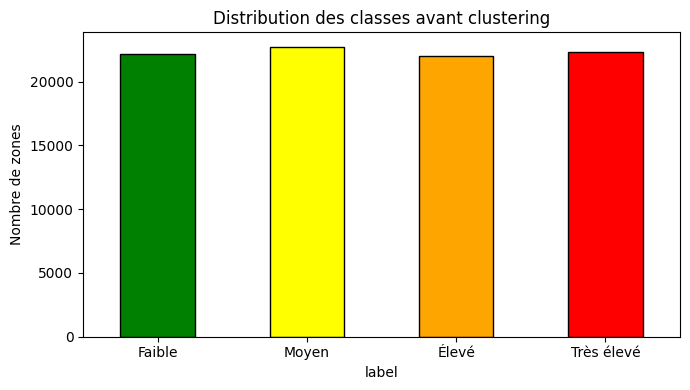

In [ ]:
def create_labels(df):
    labels = []
    for _, row in df.iterrows():
        dist = row['dist_fire_km']
        in_f = row['in_fire']
        if in_f == 1:
            labels.append(4)
        elif dist <= 3.8:    # 25% le plus proche → Très élevé
            labels.append(4)
        elif dist <= 7.1:    # 25-50% → Élevé
            labels.append(3)
        elif dist <= 11.8:   # 50-75% → Moyen
            labels.append(2)
        else:                # 75-100% → Faible
            labels.append(1)
    return labels

dataSetAlg['label'] = create_labels(dataSetAlg)

print('Distribution des classes AVANT clustering:')
print(dataSetAlg['label'].value_counts().sort_index())

plt.figure(figsize=(7, 4))
dataSetAlg['label'].value_counts().sort_index().plot(
    kind='bar',
    color=['green', 'yellow', 'orange', 'red'],
    edgecolor='black'
)
plt.xticks([0,1,2,3], ['Faible','Moyen','Élevé','Très élevé'], rotation=0)
plt.title('Distribution des classes avant clustering')
plt.ylabel('Nombre de zones')
plt.tight_layout()
plt.show()

## 4. Raffinage par clustering (K-Means)
Suppression des zones "Faible" qui ressemblent aux zones à risque élevé (comme dans le paper).

In [ ]:
# ── Définition des features ──
FEATURES = ['mean_slope', 'mean_aspect', 'ndvi_final', 'dist_residentiel_m',
            'dist_route_m', 'Elevation', 'dist_eau_m',
            'max_temperature', 'annual_precip', 'humidity', 'mean_windspeed']

scaler_cluster = StandardScaler()

print("NaN par colonne:")
print(dataSetAlg[FEATURES].isnull().sum())
print(f"\nTotal NaN: {dataSetAlg[FEATURES].isnull().sum().sum()}")

for col in FEATURES:
    dataSetAlg[col] = dataSetAlg[col].fillna(dataSetAlg[col].median())

def refine_low_class(df, features, high_class, threshold=0.3, random_state=42):
    low_mask  = df['label'] == 1
    high_mask = df['label'] == high_class
    low_data  = df[low_mask][features].copy()
    high_data = df[high_mask][features].copy()
    combined        = pd.concat([low_data, high_data])
    combined_idx    = list(low_data.index) + list(high_data.index)
    combined_labels = [0] * len(low_data) + [1] * len(high_data)
    for col in features:
        median_val = combined[col].median()
        combined[col] = combined[col].fillna(median_val)
    combined_sc = scaler_cluster.fit_transform(combined)
    kmeans = KMeans(n_clusters=2, n_init=10, max_iter=300, random_state=random_state)
    kmeans.fit(combined_sc)
    cluster_labels    = kmeans.labels_
    true_labels       = np.array(combined_labels)
    cluster_0_high    = np.mean(true_labels[cluster_labels == 0])
    cluster_1_high    = np.mean(true_labels[cluster_labels == 1])
    high_risk_cluster = 0 if cluster_0_high > cluster_1_high else 1

    # ── Calcul de la distance au centroïde à risque ──
    high_centroid = kmeans.cluster_centers_[high_risk_cluster]
    low_points    = combined_sc[:len(low_data)]
    distances     = np.linalg.norm(low_points - high_centroid, axis=1)
    max_dist      = distances.max()
    norm_dist     = distances / max_dist

    to_remove = [combined_idx[i] for i in range(len(low_data))
                 if cluster_labels[i] == high_risk_cluster
                 and norm_dist[i] < threshold]
    return to_remove

print("Raffinage en cours...")
to_remove_4 = refine_low_class(dataSetAlg, FEATURES, high_class=4, threshold=0.3)
to_remove_3 = refine_low_class(dataSetAlg, FEATURES, high_class=3, threshold=0.3)
to_remove_2 = refine_low_class(dataSetAlg, FEATURES, high_class=2, threshold=0.3)

all_to_remove = set(to_remove_4) | set(to_remove_3) | set(to_remove_2)
print(f"Zones supprimées : {len(all_to_remove)}")
print(f"Pourcentage : {len(all_to_remove)/len(dataSetAlg[dataSetAlg['label']==1])*100:.2f}%")

dataSetAlg_clean = dataSetAlg.drop(index=all_to_remove).reset_index(drop=True)
print("\nDistribution APRÈS clustering:")
print(dataSetAlg_clean['label'].value_counts().sort_index())

NaN par colonne:
mean_slope             0
mean_aspect           20
ndvi_final             0
dist_residentiel_m     0
dist_route_m           0
Elevation              0
dist_eau_m             0
max_temperature        0
annual_precip          0
humidity               0
mean_windspeed         0
dtype: int64

Total NaN: 20
Raffinage en cours...
Zones supprimées : 8278
Pourcentage : 37.37%

Distribution APRÈS clustering:
label
1    13874
2    22736
3    21999
4    22311
Name: count, dtype: int64


## 5. VIF — Vérification de la multicolinéarité
VIF > 10 ou Tolérance < 0.1 → multicolinéarité problématique.

In [ ]:
# ── Calcul VIF sur X complet avant split ──
X_vif = dataSetAlg_clean[FEATURES]
scaler_vif = StandardScaler()
X_vif_sc = pd.DataFrame(
    scaler_vif.fit_transform(X_vif),
    columns=FEATURES
)

sample_vif = X_vif_sc.sample(n=min(10000, len(X_vif_sc)), random_state=42)
vif_data = pd.DataFrame({
    'Feature': FEATURES,
    'VIF':     [variance_inflation_factor(sample_vif.values, i)
                for i in range(len(FEATURES))],
})
vif_data['Tolerance'] = 1 / vif_data['VIF']
print('\n── VIF & Tolérance ──')
print(vif_data.sort_values('VIF', ascending=False).to_string(index=False))

# ── Drop colonnes VIF > 10 ──
cols_to_drop = vif_data[vif_data['VIF'] > 10]['Feature'].tolist()
print(f"\nColonnes supprimées : {cols_to_drop}")
FEATURES = [f for f in FEATURES if f not in cols_to_drop]
print(f"Features retenues ({len(FEATURES)}) : {FEATURES}")


── VIF & Tolérance ──
           Feature      VIF  Tolerance
          humidity 8.299561   0.120488
   max_temperature 7.395527   0.135217
     annual_precip 4.360572   0.229328
         Elevation 2.559283   0.390734
        ndvi_final 2.368184   0.422264
        mean_slope 1.662640   0.601453
    mean_windspeed 1.563046   0.639776
dist_residentiel_m 1.308569   0.764194
      dist_route_m 1.156887   0.864389
        dist_eau_m 1.146078   0.872541
       mean_aspect 1.011920   0.988221

Colonnes supprimées : []
Features retenues (11) : ['mean_slope', 'mean_aspect', 'ndvi_final', 'dist_residentiel_m', 'dist_route_m', 'Elevation', 'dist_eau_m', 'max_temperature', 'annual_precip', 'humidity', 'mean_windspeed']


## 6. Préparation X / y et split Train/Test (70% / 30%)

In [ ]:
X = dataSetAlg_clean[FEATURES]
y = dataSetAlg_clean['label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc  = scaler.transform(X_test)

X_train_df = pd.DataFrame(X_train_sc, columns=FEATURES)
X_test_df  = pd.DataFrame(X_test_sc,  columns=FEATURES)

print(f'Train: {X_train_sc.shape} | Test: {X_test_sc.shape}')

Train: (56644, 11) | Test: (24276, 11)


## 7. Entraînement des modèles (RF, SVM, XGBoost)

In [ ]:
le = LabelEncoder()
y_train_enc = le.fit_transform(y_train)
y_test_enc  = le.transform(y_test)
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV

models = {
    'Random Forest': RandomForestClassifier(
        n_estimators=500, random_state=42, n_jobs=-1),
    'SVM': CalibratedClassifierCV(
        LinearSVC(random_state=42, max_iter=1000)),
    'XGBoost': XGBClassifier(
        n_estimators=500, random_state=42,
        eval_metric='mlogloss',
        device='cuda',
        n_jobs=-1)
}

results = {}

for name, model in models.items():
    print(f'\n── Entraînement : {name} ──')
    model.fit(X_train_sc, y_train_enc)
    y_pred  = model.predict(X_test_sc)
    y_proba = model.predict_proba(X_test_sc)
    acc   = accuracy_score(y_test_enc, y_pred)
    f1    = f1_score(y_test_enc, y_pred, average='weighted')
    auc   = roc_auc_score(label_binarize(y_test_enc, classes=np.unique(y_test_enc)),
                          y_proba, multi_class='ovr', average='weighted')
    prauc = average_precision_score(
                label_binarize(y_test_enc, classes=np.unique(y_test_enc)),
                y_proba, average='weighted')
    cv    = cross_val_score(model, X_train_sc, y_train_enc,
                            cv=5, scoring='accuracy', n_jobs=-1).mean()
    results[name] = {
        'Accuracy': acc, 'F1 Score': f1,
        'AUC-ROC': auc, 'PR-AUC': prauc, 'Cross-Val': cv
    }
    print(f'  Accuracy  : {acc:.4f}')
    print(f'  F1 Score  : {f1:.4f}')
    print(f'  AUC-ROC   : {auc:.4f}')
    print(f'  PR-AUC    : {prauc:.4f}')
    print(f'  Cross-Val : {cv:.4f}')
    print(classification_report(y_test_enc, y_pred))


In [ ]:
import joblib
import os

save_path = "/content/gdrive/MyDrive/Projet big data dossier organisé /modelsAlg"
os.makedirs(save_path, exist_ok=True)

for name, model in models.items():
    filename = name.replace(' ', '_').lower()
    joblib.dump(model, f"{save_path}/{filename}.pkl")
    print(f"✓ {name} sauvegardé")

joblib.dump(scaler, f"{save_path}/scaler.pkl")
joblib.dump(le,     f"{save_path}/label_encoder.pkl")

✓ Random Forest sauvegardé
✓ SVM sauvegardé
✓ XGBoost sauvegardé


['/content/gdrive/MyDrive/Projet big data dossier organisé /modelsAlg/label_encoder.pkl']

## 8. Tableau comparatif des modèles


── Comparaison des modèles ──
               Accuracy  F1 Score  AUC-ROC  PR-AUC  Cross-Val
Random Forest    0.7806    0.7804   0.9375  0.8396     0.7661
SVM              0.3871    0.3607   0.6456  0.3860     0.3892
XGBoost          0.7104    0.7094   0.9035  0.7738     0.7037


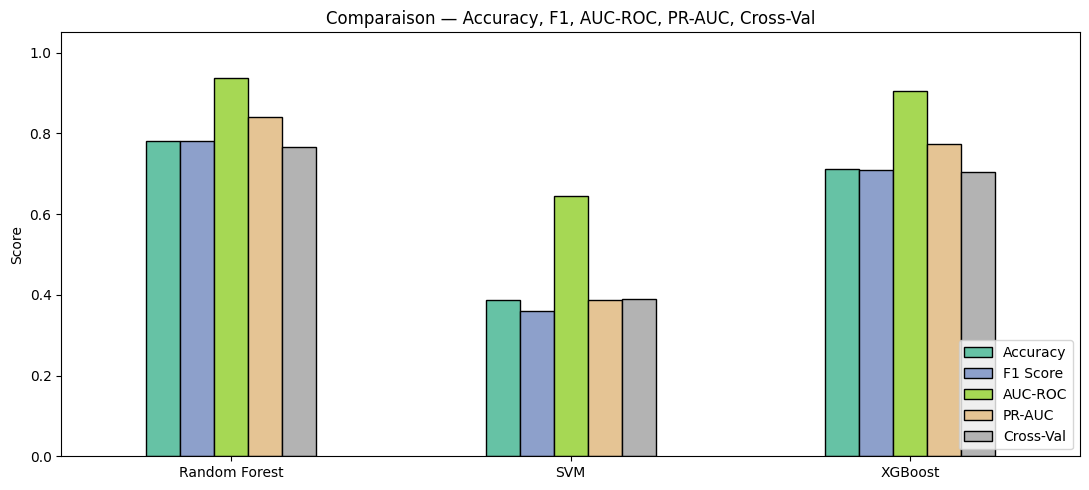

In [ ]:
results_df = pd.DataFrame(results).T
print('\n── Comparaison des modèles ──')
print(results_df.round(4))

results_df.plot(kind='bar', figsize=(11, 5),
                colormap='Set2', edgecolor='black')
plt.title('Comparaison — Accuracy, F1, AUC-ROC, PR-AUC, Cross-Val')
plt.ylabel('Score')
plt.xticks(rotation=0)
plt.ylim(0, 1.05)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

## 9. Courbes ROC et PR

In [ ]:
from sklearn.metrics import roc_curve, auc

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
colors = ['blue', 'red', 'green', 'orange']
class_names_roc = ['Faible', 'Moyen', 'Élevé', 'Très élevé']

for col, (name, model) in enumerate(models.items()):
    y_proba = model.predict_proba(X_test_sc)
    classes = np.unique(y_test_enc)
    yv_bin  = label_binarize(y_test_enc, classes=classes)

    for i, cls in enumerate(classes):
        fpr, tpr, _ = roc_curve(yv_bin[:, i], y_proba[:, i])
        roc_auc_val = auc(fpr, tpr)
        axes[0][col].plot(fpr, tpr, color=colors[i],
                          label=f'{class_names_roc[i]} (AUC={roc_auc_val:.2f})')
    axes[0][col].plot([0,1],[0,1],'k--')
    axes[0][col].set_title(f'ROC — {name}')
    axes[0][col].set_xlabel('False Positive Rate')
    axes[0][col].set_ylabel('True Positive Rate')
    axes[0][col].legend(loc='lower right', fontsize=7)

    for i, cls in enumerate(classes):
        PrecisionRecallDisplay.from_predictions(
            yv_bin[:, i], y_proba[:, i],
            name=f'{class_names_roc[i]}', ax=axes[1][col])
    axes[1][col].set_title(f'PR Curve — {name}')
    axes[1][col].legend(loc='lower left', fontsize=7)

plt.tight_layout()
plt.show()


## 10. Matrices de confusion

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
class_names = ['Faible','Moyen','Élevé','Très élevé']

for ax, (name, model) in zip(axes, models.items()):
    y_pred = model.predict(X_test_sc)
    cm     = confusion_matrix(y_test_enc, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=class_names, yticklabels=class_names)
    ax.set_title(f'Confusion Matrix — {name}')
    ax.set_xlabel('Prédit')
    ax.set_ylabel('Réel')

plt.tight_layout()
plt.show()


## 11. Analyse SHAP (XGBoost)
Explication des prédictions : quelles variables influencent le plus le risque de feu ?


── Analyse SHAP sur XGBoost ──


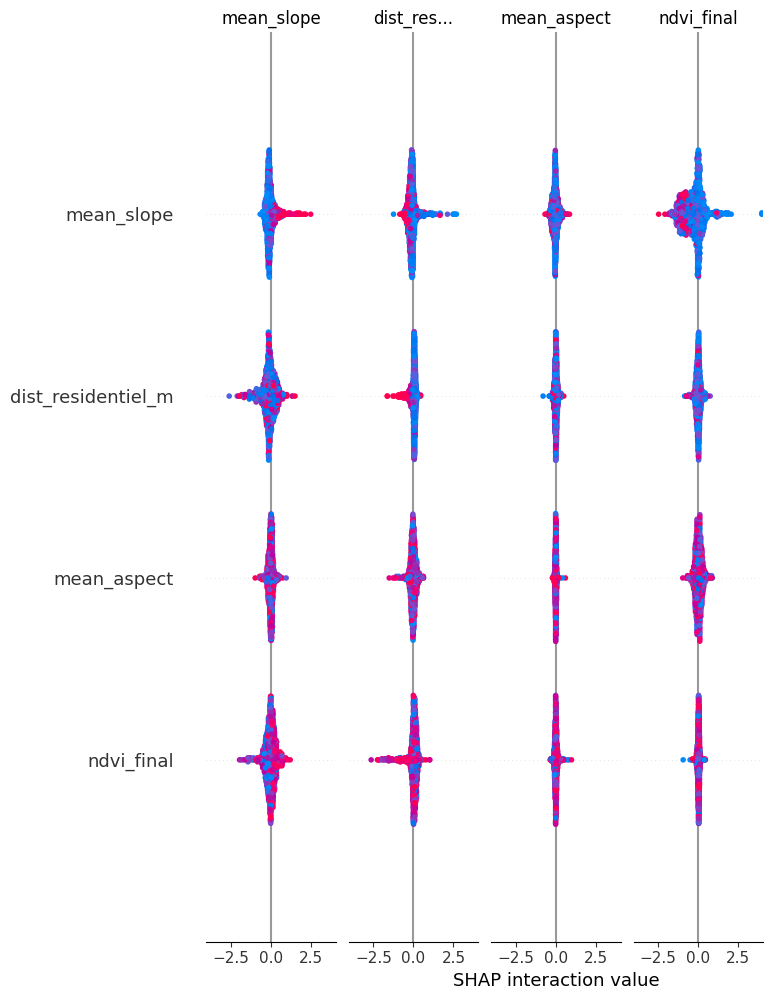

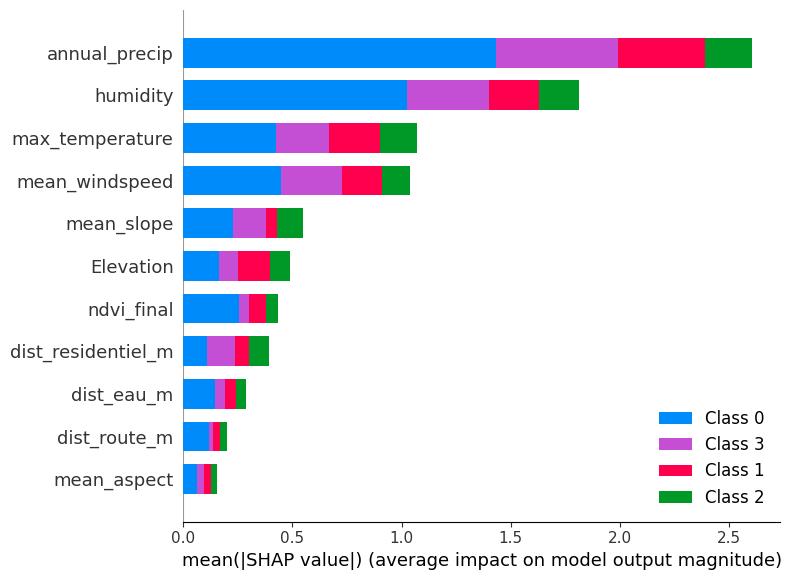

In [ ]:
print('\n── Analyse SHAP sur XGBoost ──')
sample_shap = X_test_df.sample(n=min(1000, len(X_test_df)), random_state=42)
explainer   = shap.TreeExplainer(models['XGBoost'])
shap_values = explainer.shap_values(sample_shap)

# Beeswarm plot
shap.summary_plot(shap_values, sample_shap,
                  plot_type='dot', show=True, max_display=13)

# Bar plot
shap.summary_plot(shap_values, sample_shap,
                  plot_type='bar', show=True, max_display=13)

## 12. Carte des probabilités de feu
Probabilité d'appartenir à la classe **Très élevé** pour chaque zone géographique.

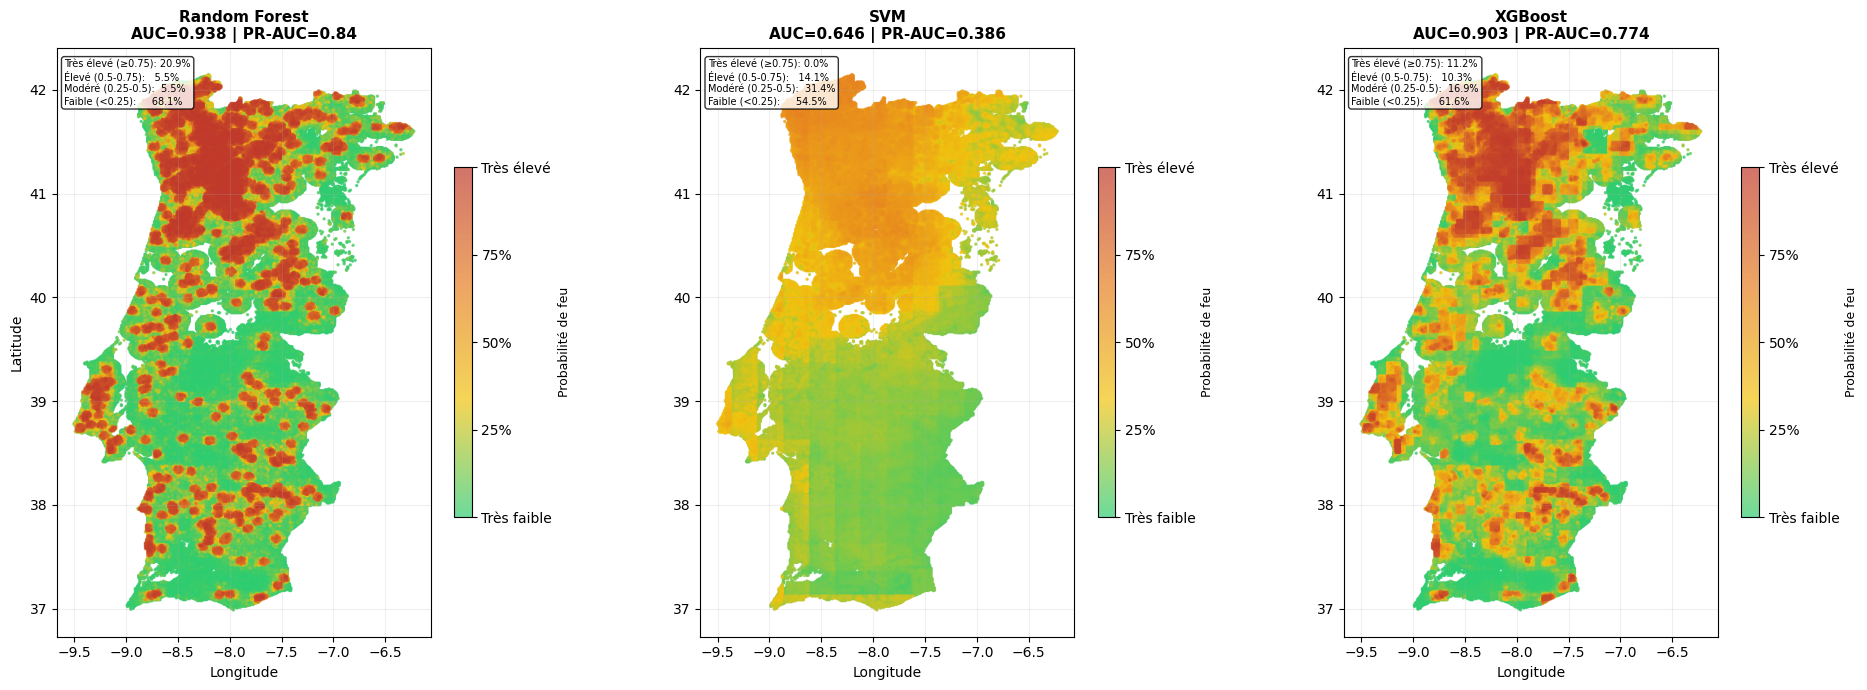

In [ ]:
X_all_sc = scaler.transform(dataSetAlg_clean[FEATURES])
lat_all  = dataSetAlg_clean['latitude'].values
lon_all  = dataSetAlg_clean['longitude'].values

all_models_names = ['Random Forest', 'SVM', 'XGBoost']
probas_all  = {}
results_all = {}

for name in all_models_names:
    proba_matrix     = models[name].predict_proba(X_all_sc)
    probas_all[name] = proba_matrix[:, -1]
    results_all[name] = {
        'AUC':    round(results[name]['AUC-ROC'], 3),
        'PR_AUC': round(results[name]['PR-AUC'],  3)
    }

cmap_fire = LinearSegmentedColormap.from_list(
    'fire_risk', ['#2ECC71', '#F1C40F', '#E67E22', '#C0392B'], N=256
)

fig, axes = plt.subplots(1, 3, figsize=(20, 7))

for i, name in enumerate(all_models_names):
    proba = probas_all[name]
    order = np.argsort(proba)
    sc = axes[i].scatter(
        lon_all[order], lat_all[order],
        c=proba[order], cmap=cmap_fire,
        vmin=0, vmax=1, s=2, alpha=0.7
    )
    cbar = plt.colorbar(sc, ax=axes[i], fraction=0.03, pad=0.04)
    cbar.set_label('Probabilité de feu', fontsize=9)
    cbar.set_ticks([0, 0.25, 0.5, 0.75, 1.0])
    cbar.set_ticklabels(['Très faible', '25%', '50%', '75%', 'Très élevé'])
    r = results_all[name]
    axes[i].set_title(
        f'{name}\nAUC={r["AUC"]} | PR-AUC={r["PR_AUC"]}',
        fontsize=11, fontweight='bold'
    )
    axes[i].set_xlabel('Longitude')
    if i == 0:
        axes[i].set_ylabel('Latitude')
    axes[i].set_aspect('equal')
    axes[i].grid(alpha=0.2)
    n_total = len(proba)
    textstr = (
        f"Très élevé (≥0.75): {(proba>=0.75).sum()/n_total*100:.1f}%\n"
        f"Élevé (0.5-0.75):   {((proba>=0.5)&(proba<0.75)).sum()/n_total*100:.1f}%\n"
        f"Modéré (0.25-0.5):  {((proba>=0.25)&(proba<0.5)).sum()/n_total*100:.1f}%\n"
        f"Faible (<0.25):     {(proba<0.25).sum()/n_total*100:.1f}%"
    )
    axes[i].text(0.02, 0.98, textstr,
                 transform=axes[i].transAxes, fontsize=7,
                 verticalalignment='top',
                 bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

plt.tight_layout()
plt.show()


Comme la methode de Uthappa(india paper) retourne la prediction feu/ non , tandis que la methode presente dans ce notebook cree des classe ( risque tres eleve wildfire , eleve , moyen et faible ) pour comparer il faut revenir a une base commune donc on merge nos classe , on considere que eleve et tres eleve corespond au label wild , le reste pas feu

Fusion des Class pour pouvoir comparez les différentes methodes

In [ ]:
from sklearn.metrics import roc_auc_score, precision_recall_curve, auc as pr_auc_score
from sklearn.metrics import average_precision_score

y_test_binary  = (y_test_enc >= 2).astype(int)
y_train_binary = (y_train_enc >= 2).astype(int)

print("\n── Métriques comparatives — Binaire (feu vs non-feu) ──")
print("="*65)
print(f"\n{'Metric':<25} {'SVM':>10} {'RF':>10} {'XGBoost':>10}")
print("-"*65)

metrics_compare = {}

for name, model in models.items():
    y_proba_test  = model.predict_proba(X_test_sc)
    y_proba_train = model.predict_proba(X_train_sc)

    proba_fire_test  = y_proba_test[:, 2]  + y_proba_test[:, 3]
    proba_fire_train = y_proba_train[:, 2] + y_proba_train[:, 3]

    roc_test  = round(roc_auc_score(y_test_binary,  proba_fire_test),  3)
    roc_train = round(roc_auc_score(y_train_binary, proba_fire_train), 3)

    prec, rec, _       = precision_recall_curve(y_test_binary,  proba_fire_test)
    pr_test            = round(pr_auc_score(rec, prec), 3)

    prec_tr, rec_tr, _ = precision_recall_curve(y_train_binary, proba_fire_train)
    inner_ap           = round(pr_auc_score(rec_tr, prec_tr), 3)

    gap = round(roc_train - roc_test, 3)

    metrics_compare[name] = {
        'ROC-AUC (test)':      roc_test,
        'PR-AUC (test)':       pr_test,
        'Generalisation gap':  gap,
        'Inner AP':            inner_ap,
        'Avg. trees':          500 if name != 'SVM' else 'N/A'
    }

rows = ['ROC-AUC (test)', 'PR-AUC (test)', 'Generalisation gap', 'Inner AP', 'Avg. trees']
for row in rows:
    print(f"{row:<25}", end="")
    for name in ['SVM', 'Random Forest', 'XGBoost']:
        val = metrics_compare[name][row]
        if isinstance(val, float):
            print(f"{val:>10.3f}", end="")
        else:
            print(f"{val:>10}", end="")
    print()

print("="*65)
print("\n  Notre solution (LightGBM + spatial CV) :")
print("  ROC-AUC=0.846 | PR-AUC=0.423 | Gap=0.042 | Inner AP=0.495 | Trees=29")
